# Dogs vs Cats Classification using Transfer Learning (VGG16)

Instead of training a CNN from scratch, this notebook reuses **VGG16 pretrained on ImageNet** as a frozen feature extractor
and trains only a small classifier on top. Within **5 epochs** it reaches **98.74% validation accuracy**, compared with
about 90% for the from-scratch CNN trained for 20 epochs (`CNN_mini_project.ipynb`).

**Workflow:** `Input -> VGG16 (frozen conv base) -> Global Average Pooling -> Dense -> Dropout -> Output`

| Item | Value |
|---|---|
| Dataset | [Dogs vs Cats (Kaggle, `salader/dogsvscats`)](https://www.kaggle.com/datasets/salader/dogsvscats) |
| Train / validation images | 20,000 / 5,000 |
| Input size | 224 x 224 x 3 (VGG16 input size) |
| Pretrained model | VGG16, ImageNet weights, convolutional base only |
| Task | Binary classification (sigmoid output) |
| Framework | TensorFlow / Keras |

## 1. Data Setup

Download the dataset from Kaggle (requires a `kaggle.json` API token) and extract it.

In [1]:
# Upload the Kaggle API token (kaggle.json)
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [2]:
# Install the Kaggle CLI and register the API token
!pip install -q kaggle

import os
import shutil

os.makedirs('/root/.kaggle', exist_ok=True)
shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')

# The token must be readable only by the owner
os.chmod('/root/.kaggle/kaggle.json', 0o600)

In [3]:
# Download the Dogs vs Cats dataset
!kaggle datasets download -d salader/dogsvscats

In [4]:
# Extract the archive into /content (creates /content/train and /content/test)
import zipfile

with zipfile.ZipFile('/content/dogsvscats.zip', 'r') as zip_ref:
    zip_ref.extractall('/content')

## 2. Imports

In [5]:
import glob
import random

import numpy as np
import matplotlib.pyplot as plt
import cv2

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

## 3. Data Loading and Preprocessing

- Images are read from folders; the class label is inferred from the folder name (`cats` / `dogs`).
- Every image is resized to **224 x 224**, the input size VGG16 was trained on, and batched (32 images per batch).
- Pixels are **not** divided by 255. VGG16's own `preprocess_input` is used instead (RGB to BGR and subtraction of the
  ImageNet channel means), because the pretrained weights expect exactly this input distribution.

In [6]:
# Training and validation datasets (labels inferred from sub-folder names)
train_ds = keras.utils.image_dataset_from_directory(
    directory='/content/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(224, 224)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory='/content/test',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(224, 224)
)

# Apply the official VGG16 preprocessing to every batch
def process(image, label):
    image = preprocess_input(image)
    return image, label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


## 4. Model: Frozen VGG16 + New Classifier Head

- **Base:** VGG16 without its original 1000-class classifier (`include_top=False`), loaded with ImageNet weights.
  It outputs a `7 x 7 x 512` feature map for a 224 x 224 input.
- **Frozen:** `base_model.trainable = False`, so the 14.7M pretrained weights are not updated. Only the new head is trained.
- **Global Average Pooling:** averages each 7 x 7 feature map into one value (512 values in total). Compared with `Flatten`
  (25,088 values), this removes about 6.3M parameters from the next dense layer and reduces overfitting.
- **Dense 256 + Dropout 0.5:** learns the cat/dog decision from the pretrained features; dropout randomly disables half of
  the neurons during training for regularization.
- **Output:** one sigmoid neuron giving the probability that the image is a dog.

In [7]:
# Load VGG16 pretrained on ImageNet, without its original classifier
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers so only the new head is trained
base_model.trainable = False

# Add a new classification head on top of the frozen base
model = models.Sequential([
    base_model,                                # 224x224x3 -> 7x7x512 feature maps
    layers.GlobalAveragePooling2D(),           # 7x7x512 -> 512
    layers.Dense(256, activation='relu'),      # 512 -> 256
    layers.Dropout(0.5),                       # regularization
    layers.Dense(1, activation='sigmoid')      # probability of "dog"
])

In [8]:
# Layer-by-layer output shapes; note that only 131,585 of 14.8M parameters are trainable
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 5. Compile and Train

- **Optimizer:** Adam with a small learning rate (`1e-4`) for stable training of the new head
- **Loss:** binary cross-entropy (two classes, sigmoid output)
- **Metric:** accuracy
- **Epochs:** 5. Backpropagation only updates the head; the frozen VGG16 layers are used in the forward pass but receive no weight updates.

In [9]:
# Configure the learning process
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [10]:
# Train for 5 epochs, evaluating on the validation set after each epoch
history = model.fit(
    train_ds,
    epochs=5,
    validation_data=validation_ds
)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 120s 192ms/step - accuracy: 0.9808 - loss: 0.0580 - val_accuracy: 0.9850 - val_loss: 0.0468
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 121s 193ms/step - accuracy: 0.9839 - loss: 0.0460 - val_accuracy: 0.9844 - val_loss: 0.0422
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 142s 193ms/step - accuracy: 0.9844 - loss: 0.0455 - val_accuracy: 0.9850 - val_loss: 0.0404
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 120s 193ms/step - accuracy: 0.9863 - loss: 0.0379 - val_accuracy: 0.9852 - val_loss: 0.0390
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 121s 193ms/step - accuracy: 0.9890 - loss: 0.0308 - val_accuracy: 0.9874 - val_loss: 0.0371


## 6. Training Results

| Epoch | Train accuracy | Train loss | Validation accuracy | Validation loss |
|---|---|---|---|---|
| 1 | 98.08% | 0.0580 | 98.50% | 0.0468 |
| 2 | 98.39% | 0.0460 | 98.44% | 0.0422 |
| 3 | 98.44% | 0.0455 | 98.50% | 0.0404 |
| 4 | 98.63% | 0.0379 | 98.52% | 0.0390 |
| 5 | 98.90% | 0.0308 | **98.74%** | **0.0371** |

**Analysis**

- **Strong from the first epoch:** validation accuracy is already 98.50% after epoch 1, well above the best result of the
  from-scratch CNN (about 90% after 20 epochs). The pretrained features do most of the work and the new head only has
  to learn how to read them.
- **No overfitting:** training and validation accuracy differ by only about 0.2 points (98.90% vs 98.74%), and validation
  loss decreases every epoch. The from-scratch CNN showed a gap of about 9 points.
  Training accuracy is measured with dropout active, so it slightly understates the model's true training performance.
- **Stable training:** validation accuracy stays between 98.44% and 98.74%, while the from-scratch CNN swung between 83.6% and 90.1%.
- **Why it works:** VGG16 was trained on 1.28 million ImageNet images that include many dog breeds and several cat
  categories, so its filters already detect fur texture, ears, snouts and eyes. Only 131,585 parameters (0.9%) are trained,
  which leaves little room to memorize the 20,000 training images.
- **Remaining errors:** about 1.26% of validation images (roughly 63 of 5,000) are still misclassified. Validation loss is
  still falling at epoch 5, so a few more epochs, or fine-tuning the last convolution block with a very low learning rate,
  could improve it further.

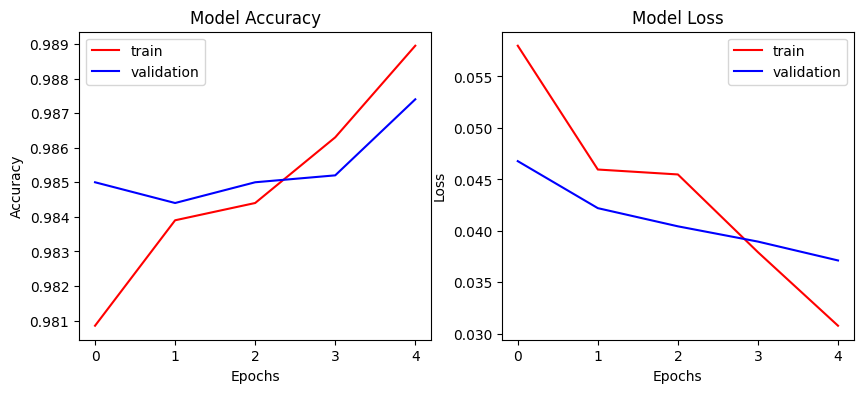

In [11]:
plt.figure(figsize=(10, 4))

# Accuracy curves
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss curves
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

## 7. Prediction on a New Image

`predict()` applies the same preprocessing used in training (RGB conversion, resize to 224 x 224, VGG16 `preprocess_input`,
batch dimension) and thresholds the sigmoid output at 0.5.

In [12]:
def predict(image_path):
    """Classify a single image as Cat or Dog and display it with the confidence."""
    # Read the image (OpenCV loads BGR) and convert to RGB
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Image not found: {image_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize to the VGG16 input size
    img_resized = cv2.resize(img, (224, 224))

    # Keep an unscaled copy for display
    img_display = img_resized.copy()

    # Same preprocessing as training (VGG16 mean subtraction), plus batch dimension
    img_preprocessed = preprocess_input(img_resized.astype(np.float32))
    img_preprocessed = np.expand_dims(img_preprocessed, axis=0)

    # Sigmoid output = probability of class 1 (dog)
    probability = float(model.predict(img_preprocessed, verbose=0)[0][0])

    if probability >= 0.5:
        label, confidence = "Dog 🐶", probability * 100
    else:
        label, confidence = "Cat 🐱", (1 - probability) * 100

    # Show the image with its prediction
    plt.figure(figsize=(5, 5))
    plt.imshow(img_display)
    plt.title(f"{label}\nConfidence: {confidence:.2f}%")
    plt.axis('off')
    plt.show()

    print(f"Prediction: {label}")
    print(f"Dog Probability: {probability * 100:.2f}%")
    print(f"Cat Probability: {(1 - probability) * 100:.2f}%")

    return label, probability

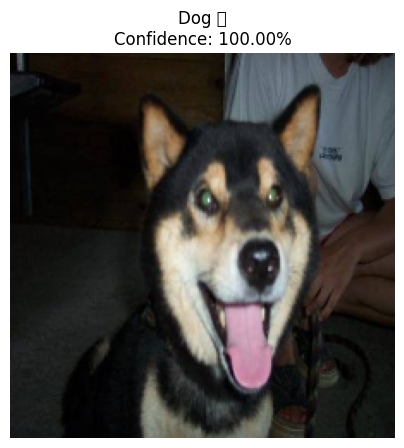

Prediction: Dog 🐶
Dog Probability: 100.00%
Cat Probability: 0.00%


('Dog 🐶', 1.0)

In [13]:
# Example: classify a randomly chosen dog image from the validation folder
dog_paths = glob.glob('/content/test/dogs/*')
random_sample_path = random.choice(dog_paths)

predict(random_sample_path)